# Resultado calificación total del modelo CAMEL

Para obtener la calificación total (usando todos los indicadores previamente calculados) se tienen los siguientes pasos:

1. Descarga y lectura de los datos (Resultado de calificación individual de los indicadores).
2. Extracción y valoración del PCA.
3. Creación de los rangos (percentiles para las variables).
4. Calificación modelo CAMEL - general.
5. Calificación modelo CAMEL - sectorizado

# 1. Extracción de datos

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


In [2]:
data_dir = Path().resolve().parent / "data" / "camel"
filepath = data_dir / "Registros_CAMEL_sin_solvencia_categorizados.csv"
datos=pd.read_csv(filepath)
datos.head()

,ID_registro,ano,mes,ID_indicador,ID_cooperativa,valor,categoria
0,1,2022,1,Quebranto Patrimonial,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,1.265719,Micro 1
1,3,2022,1,Relación entre Aportes sociales mínimos no red...,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,0.431216,Micro 1
2,4,2022,1,Relación entre el Capital Institucional y el A...,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,0.067410,Micro 1
3,5,2022,2,Quebranto Patrimonial,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,1.270411,Micro 1
4,7,2022,2,Relación entre Aportes sociales mínimos no red...,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,0.430248,Micro 1


In [3]:
# en la columna "valor" cambiar nulos por o
datos["valor"] = datos["valor"].fillna(0)
#cuando el valor de la columna "valor" sea ' ', cambiarlo por 0
datos["valor"] = datos["valor"].replace(' ', 0)
#cambiar el tipo de dato de la columna "valor" a float
datos["valor"] = datos["valor"].astype(float)
#cambia top 4
datos.loc[datos["categoria"] == "Top 4", "categoria"] = "Megas"
#'Micro 1', 'Medianas', 'Megas', 'Pequeñas', 'Grandes', 'Micro 2','Top 4'

In [4]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133284 entries, 0 to 133283
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   ID_registro     133284 non-null  int64  
 1   ano             133284 non-null  int64  
 2   mes             133284 non-null  int64  
 3   ID_indicador    133284 non-null  object 
 4   ID_cooperativa  133284 non-null  object 
 5   valor           133284 non-null  float64
 6   categoria       133284 non-null  object 
dtypes: float64(1), int64(3), object(3)
memory usage: 7.1+ MB


# 2. Cálculo PCA

In [5]:
def pesos_pca_grupo_coops(
    df,
    lista_coops,
    col_nombre="ID_cooperativa",
    n_componentes=3
):
    
    # filtrar cooperativas
    df_filtrado = df[df[col_nombre].isin(lista_coops)].copy()
    
    if df_filtrado.empty:
        raise ValueError("No hay datos para las cooperativas indicadas")
    
    # LIMPIEZA 
    df_filtrado["valor"] = (
        df_filtrado["valor"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    
    df_filtrado["valor"] = pd.to_numeric(df_filtrado["valor"], errors="coerce")
    
    # pivot (matriz indicadores)
    df_pivot = df_filtrado.pivot_table(
        index=col_nombre,
        columns="ID_indicador",
        values="valor",
        aggfunc="mean"
    )
    
    # imputar faltantes
    imputer = SimpleImputer(strategy="mean")
    X_imputed = imputer.fit_transform(df_pivot)
    
    # escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imputed)
    
    # PCA
    pca = PCA(n_components=min(n_componentes, df_pivot.shape[1]))
    pca.fit(X_scaled)
    
    X_pca = pca.transform(X_scaled)
    
    loadings = pd.DataFrame(
        pca.components_.T,
        index=df_pivot.columns
    )
    
    pesos = (loadings**2).mean(axis=1)
    pesos = (pesos / pesos.sum())

    pesos_ponderados = np.sum(
        (loadings.iloc[:, :n_componentes]**2)*pca.singular_values_[:n_componentes], 
        axis=1
        )
    pesos_ponderados = (pesos_ponderados / pesos_ponderados.sum())

    # Varianza acumulada
    cumulative_variance = pd.DataFrame(
    np.cumsum(pca.explained_variance_ratio_), 
    index=[f"PC{i+1}" for i in range(X_pca.shape[1])], 
    columns=["Cumulative Explained Variance"]
    )

    return pesos, pesos_ponderados, cumulative_variance

In [6]:
lista_coops = datos["ID_cooperativa"].unique().tolist()
pesos, pesos_ponderados, cumulative_variance = pesos_pca_grupo_coops(
    df=datos,
    lista_coops=lista_coops,
    col_nombre="ID_cooperativa",
    n_componentes=6
)

print("Pesos PCA:")
print(pesos.sort_values(ascending=False))

Pesos PCA:
ID_indicador
Indicador de Riesgo de Liquidez - IRL                                                     0.141980
Indicador de calidad por riesgo con castigos                                              0.113808
Indicador de relación entre las obligaciones financieras y el pasivo total                0.109550
Indicador de rentabilidad sobre recursos propios - ROE                                    0.095248
Indicador de rentabilidad sobre el capital invertido - ROIC                               0.071793
Estructura de Balance                                                                     0.068373
Indicador de margen neto                                                                  0.059192
Indicador de Margen Operacional                                                           0.057676
Indicador de calidad por riesgo                                                           0.054197
Indicador de Cobertura de la Cartera Total en Riesgo                                 

In [7]:
print("\nVarianza acumulada:")
print(cumulative_variance)


Varianza acumulada:
     Cumulative Explained Variance
PC1                       0.377471
PC2                       0.568265
PC3                       0.670973
PC4                       0.737128
PC5                       0.790822
PC6                       0.830710


In [8]:
print("\nPesos ponderados PCA:")
print(pesos_ponderados.sort_values(ascending=False))


Pesos ponderados PCA:
ID_indicador
Indicador de Riesgo de Liquidez - IRL                                                     0.104647
Indicador de relación entre las obligaciones financieras y el pasivo total                0.087042
Indicador de rentabilidad sobre recursos propios - ROE                                    0.086528
Indicador de calidad por riesgo con castigos                                              0.085794
Indicador de rentabilidad sobre el capital invertido - ROIC                               0.075651
Indicador de margen neto                                                                  0.066536
Indicador de Margen Operacional                                                           0.064553
Estructura de Balance                                                                     0.060837
Indicador de calidad por riesgo                                                           0.057843
Indicador de Cobertura de la Cartera Total en Riesgo                     

# 3. Cálculo Rangos

In [9]:
INDICADORES_INVERSOS = [
    "Indicador de calidad por riesgo",
    "Indicador de calidad por riesgo con castigos",
    "Indicador de Cobertura de la Cartera Total en Riesgo",
    "Indicador de relación entre las obligaciones financieras y el pasivo total",
    "Indicador de Margen Financiero de Operación",
    "Indicador de Margen Operacional"
]

INDICADOR_SOLVENCIA = "Relación Solvencia"
INDICADOR_IRL = "IRL"

PERCENTILES = [20, 40, 60, 80]


# ======================================================
# CALCULAR PERCENTILES
# ======================================================

def calcular_percentiles(df, indicadores):

    resultados = {}

    primer_corte = PERCENTILES[0]          # 20
    cortes_restantes = PERCENTILES[1:]     # [40, 60, 80]

    for indicador in indicadores:

        subset = df[df["ID_indicador"] == indicador].copy()

        if subset.empty:
            continue

        valores = subset["valor"].dropna()

        # ----------------------------------
        # IRL → aplicar log10(x)
        # ----------------------------------
        if indicador== INDICADOR_IRL:

            valores = valores[valores > 0]

            if len(valores) == 0:
                continue

            valores = np.log10(valores)

        # ----------------------------------
        # Detectar muchos ceros
        # ----------------------------------
        porcentaje_ceros = (valores == 0).mean()

        if porcentaje_ceros >= 0.10:

            valores_sin_cero = valores[valores > 0]

            p = {}

            # Primer corte = 0
            p[primer_corte] = 0

            if len(valores_sin_cero) > 0:

                for q in cortes_restantes:

                    q_ajustado = (q - primer_corte) / (100 - primer_corte)

                    p[q] = valores_sin_cero.quantile(q_ajustado)

            else:

                for q in cortes_restantes:
                    p[q] = 0

        else:

            p = {
                q: valores.quantile(q / 100)
                for q in PERCENTILES
            }

        # ----------------------------------
        # Relación solvencia → primer corte = 9
        # ----------------------------------
        if indicador == INDICADOR_SOLVENCIA:

            p[primer_corte] = 9

            for q in cortes_restantes:

                p[q] = max(
                    p[q],
                    p[primer_corte]
                )

        resultados[indicador] = p

    return resultados

# ======================================================
# ASIGNAR CALIFICACIÓN
# ======================================================

def asignar_calificacion(valor, cortes, inverso=False):

    limites = sorted(cortes.items())

    if not inverso:

        for i, (_, limite) in enumerate(limites):

            if valor <= limite:
                return i + 1

        return 5

    else:

        limites_valores = [x[1] for x in limites]

        for i, limite in enumerate(reversed(limites_valores)):

            if valor >= limite:
                return i + 1

        return 5


# ======================================================
# CALIFICAR DATAFRAME
# ======================================================

def calificar_dataframe(df):

    df = df.copy()

    indicadores = df["ID_indicador"].unique()

    percentiles = calcular_percentiles(
        df,
        indicadores
    )

    calificaciones = []

    for _, row in df.iterrows():

        indicador = row["ID_indicador"]

        valor = row["valor"]

        if pd.isna(valor):
            calificaciones.append(None)
            continue

        # -------------------------
        # IRL → aplicar log10
        # -------------------------
        if indicador == INDICADOR_IRL:

            if valor <= 0:
                calificaciones.append(None)
                continue

            valor = np.log10(valor)

        inverso = indicador in INDICADORES_INVERSOS

        nota = asignar_calificacion(
            valor=valor,
            cortes=percentiles[indicador],
            inverso=inverso
        )

        calificaciones.append(nota)

    df["calificacion"] = calificaciones

    return df, percentiles

In [10]:
df,percentiles=calificar_dataframe(datos)
percentiles_df = pd.DataFrame(percentiles).T
percentiles_df

,20,40,60,80
Quebranto Patrimonial,0.0,1.267154,1.403791,1.719225
Relación entre Aportes sociales mínimos no reducibles y Capital Social,0.0,0.488339,0.658402,0.817243
Relación entre el Capital Institucional y el Activo Total,0.0,0.057018,0.080551,0.115979
Indicador de calidad por riesgo,0.0,0.047890,0.069373,0.097683
Indicador de calidad por riesgo con castigos,0.0,0.007387,0.022990,0.054017
Activo Productivo,0.0,0.802521,0.862096,0.906043
Indicador de Cobertura de la Cartera Total en Riesgo,0.0,0.035941,0.054778,0.080657
Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,0.0,0.416283,0.559822,0.687617
Estructura de Balance,0.0,1.262333,1.471650,2.016463
Indicador de Margen Financiero de Operación,0.0,0.606643,0.714179,0.811473


In [11]:
def calcular_calificaciones_formato_lista(df: pd.DataFrame, nombre_categoria: str):

    if df.empty:
        return []

    columnas_necesarias = {
        'ID_indicador',
        'ID_cooperativa',
        'valor'
    }

    if not columnas_necesarias.issubset(df.columns):
        raise ValueError("Faltan columnas necesarias")

    df = df.copy()

    # ---------------------------------
    # Calcular percentiles (tu lógica)
    # ---------------------------------
    indicadores = df["ID_indicador"].unique()

    percentiles = calcular_percentiles(
        df,
        indicadores
    )

    resultados_temp = []

    # ---------------------------------
    # Calificar fila por fila
    # ---------------------------------
    for _, row in df.iterrows():

        indicador = row["ID_indicador"]
        cooperativa = row["ID_cooperativa"]
        valor = row["valor"]

        if pd.isna(valor):
            continue

        # IRL → log10
        if indicador == INDICADOR_IRL:

            if valor <= 0:
                continue

            valor = np.log10(valor)

        inverso = indicador in INDICADORES_INVERSOS

        calificacion = asignar_calificacion(
            valor=valor,
            cortes=percentiles[indicador],
            inverso=inverso
        )

        resultados_temp.append({
            "ID_cooperativa": str(cooperativa),
            "ID_indicador": str(indicador),
            "calificacion": int(calificacion)
        })

    # ---------------------------------
    # Promediar si una cooperativa
    # tiene varias filas del mismo indicador
    # ---------------------------------
    df_result = pd.DataFrame(resultados_temp)

    if df_result.empty:
        return []

    df_result = (
        df_result
        .groupby(
            ["ID_cooperativa", "ID_indicador"],
            as_index=False
        )["calificacion"]
        .mean()
        .round()
        .astype({
            "calificacion": int
        })
    )

    # ---------------------------------
    # Construir formato final
    # ---------------------------------
    resultado_final = {}

    for _, row in df_result.iterrows():

        coop = row["ID_cooperativa"]
        indicador = row["ID_indicador"]
        calificacion = row["calificacion"]

        if coop not in resultado_final:

            resultado_final[coop] = {
                "ID_cooperativa": coop,
                "calificaciones": {}
            }

        resultado_final[coop]["calificaciones"][
            indicador
        ] = calificacion
    #df_result.to_excel(f"../../tablas/camel/Calificaciones_individuales_{nombre_categoria}_CAMEL.xlsx", index=False)
    return list(resultado_final.values())

In [12]:
def calcular_camel(lista, pesos):
    # Normalizar pesos
    #pesos_norm = pesos / pesos.sum()
    
    resultados = []

    for coop in lista:
        nombre = coop["ID_cooperativa"]
        califs = coop["calificaciones"]

        score = 0

        for indicador, peso in pesos.items():
            calificacion = califs.get(indicador, 0)  # si falta, toma 0
            score += calificacion * peso

        resultados.append({
            "ID_cooperativa": nombre,
            "CAMEL_score": score
        })

    return pd.DataFrame(resultados)

In [13]:
# Calcular CAMEL para todas las cooperativas
calificaciones=calcular_calificaciones_formato_lista(datos, nombre_categoria="general")
df_calificaciones = pd.json_normalize(calificaciones)
df_calificaciones.columns = df_calificaciones.columns.str.replace("calificaciones.", "", regex=False)
df_calificaciones = df_calificaciones.set_index("ID_cooperativa")
df_calificaciones = df_calificaciones.iloc[:-2]
df_calificaciones

,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,Indicador de margen neto,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total
ID_cooperativa,,,,,,,,,,,,,,,,
AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,3,3,3,3,2,2,3
CAJA COOPERATIVA CREDICOOP,4,4,2,4,2,4,5,1,1,1,3,1,1,3,5,4
CAJA COOPERATIVA PETROLERA,4,4,2,4,3,4,3,2,1,2,2,2,2,3,4,3
CASA NACIONAL DEL PROFESOR,4,3,4,4,4,3,2,4,4,2,2,2,2,2,4,2
CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,3,4,2,2,5,2,2,4,4,4,3,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FINANCIERA ENERGETICA COOPERATIVA LTDA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1
FORJAR CAJA COOPERATIVA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1
GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURSOS NATURALES,5,5,3,2,1,3,5,3,4,5,4,4,4,4,2,5


In [14]:
df_calificaciones = pd.merge(
    df_calificaciones,
    datos[["ID_cooperativa", "categoria"]].drop_duplicates(),
    on="ID_cooperativa",
    how="left"
)

df_calificaciones

,ID_cooperativa,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,Indicador de margen neto,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total,categoria
0,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,3,3,3,3,2,2,3,Micro 1
1,CAJA COOPERATIVA CREDICOOP,4,4,2,4,2,4,5,1,1,1,3,1,1,3,5,4,Medianas
2,CAJA COOPERATIVA PETROLERA,4,4,2,4,3,4,3,2,1,2,2,2,2,3,4,3,Megas
3,CASA NACIONAL DEL PROFESOR,4,3,4,4,4,3,2,4,4,2,2,2,2,2,4,2,Megas
4,CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,3,4,2,2,5,2,2,4,4,4,3,2,2,2,Pequeñas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167,FINANCIERA ENERGETICA COOPERATIVA LTDA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas
168,FORJAR CAJA COOPERATIVA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas
169,GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURS...,5,5,3,2,1,3,5,3,4,5,4,4,4,4,2,5,Micro 1
170,LA COOPERATIVA DE AHORRO Y CREDITO SUCREDITO,5,4,4,2,3,2,3,3,4,4,1,4,4,2,4,2,Micro 1


In [18]:
camel_pesos_sin_ponderar = calcular_camel(calificaciones, pesos)
camel_pesos_sin_ponderar.sort_values(by="CAMEL_score", ascending=False)

,ID_cooperativa,CAMEL_score
30,COOPERATIVA DE AHORRO Y CREDITO DE EMPLEADOS D...,4.089083
169,GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURS...,3.963884
42,COOPERATIVA DE AHORRO Y CREDITO DE TRABAJADORE...,3.961768
166,FINANCIERA COOPERATIVA COLOMBIANA DE INGENIEROS,3.954799
124,COOPERATIVA LEON XIII LTDA DE GUATAPE,3.859410
...,...,...
148,COOPERATIVA PIO XLL DE COCORNA,2.217631
159,COPERATIVA DE AHORRO Y CREDITO LA BELLEZA LTDA.,2.217631
146,COOPERATIVA NACIONAL EDUCATIVA DE AHORRO Y CRE...,2.121955
51,COOPERATIVA DE AHORRO Y CREDITO LA GRANJA LTDA.,2.066497


In [19]:
camel_pesos_ponderados = calcular_camel(calificaciones, pesos_ponderados)
camel_pesos_ponderados.sort_values(by="CAMEL_score", ascending=False)

,ID_cooperativa,CAMEL_score
166,FINANCIERA COOPERATIVA COLOMBIANA DE INGENIEROS,3.983965
30,COOPERATIVA DE AHORRO Y CREDITO DE EMPLEADOS D...,3.978123
124,COOPERATIVA LEON XIII LTDA DE GUATAPE,3.900311
169,GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURS...,3.831296
42,COOPERATIVA DE AHORRO Y CREDITO DE TRABAJADORE...,3.809929
...,...,...
148,COOPERATIVA PIO XLL DE COCORNA,2.176715
168,FORJAR CAJA COOPERATIVA,2.176715
159,COPERATIVA DE AHORRO Y CREDITO LA BELLEZA LTDA.,2.176715
167,FINANCIERA ENERGETICA COOPERATIVA LTDA,2.176715


In [21]:
df_calificaciones

,ID_cooperativa,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,Indicador de margen neto,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total,categoria
0,AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,3,3,3,3,2,2,3,Micro 1
1,CAJA COOPERATIVA CREDICOOP,4,4,2,4,2,4,5,1,1,1,3,1,1,3,5,4,Medianas
2,CAJA COOPERATIVA PETROLERA,4,4,2,4,3,4,3,2,1,2,2,2,2,3,4,3,Megas
3,CASA NACIONAL DEL PROFESOR,4,3,4,4,4,3,2,4,4,2,2,2,2,2,4,2,Megas
4,CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,3,4,2,2,5,2,2,4,4,4,3,2,2,2,Pequeñas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167,FINANCIERA ENERGETICA COOPERATIVA LTDA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas
168,FORJAR CAJA COOPERATIVA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas
169,GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURS...,5,5,3,2,1,3,5,3,4,5,4,4,4,4,2,5,Micro 1
170,LA COOPERATIVA DE AHORRO Y CREDITO SUCREDITO,5,4,4,2,3,2,3,3,4,4,1,4,4,2,4,2,Micro 1


In [22]:
calificaciones_camel = pd.merge(
    df_calificaciones.set_index("ID_cooperativa"), 
    camel_pesos_sin_ponderar.set_index("ID_cooperativa"), 
    left_index=True, 
    right_index=True,
    how="left"
)

calificaciones_camel = pd.merge(
    calificaciones_camel, 
    camel_pesos_ponderados.set_index("ID_cooperativa"), 
    left_index=True, 
    right_index=True,
    how="left",
    suffixes=('_sin_ponderar', '_ponderado')
)

calificaciones_camel

,Activo Productivo,Estructura de Balance,Indicador de Cobertura de la Cartera Total en Riesgo,Indicador de Cobertura individual de la cartera improductiva para la cartera en Riesgo,Indicador de Margen Financiero de Operación,Indicador de Margen Operacional,Indicador de Riesgo de Liquidez - IRL,Indicador de calidad por riesgo,Indicador de calidad por riesgo con castigos,Indicador de margen neto,Indicador de relación entre las obligaciones financieras y el pasivo total,Indicador de rentabilidad sobre el capital invertido - ROIC,Indicador de rentabilidad sobre recursos propios - ROE,Quebranto Patrimonial,Relación entre Aportes sociales mínimos no reducibles y Capital Social,Relación entre el Capital Institucional y el Activo Total,categoria,CAMEL_score_sin_ponderar,CAMEL_score_ponderado
ID_cooperativa,,,,,,,,,,,,,,,,,,,
AVANCOP COOPERATIVA DE AHORRO Y CREDITO,4,4,1,3,2,3,3,2,2,3,3,3,3,2,2,3,Micro 1,2.752045,2.728709
CAJA COOPERATIVA CREDICOOP,4,4,2,4,2,4,5,1,1,1,3,1,1,3,5,4,Medianas,2.719605,2.716819
CAJA COOPERATIVA PETROLERA,4,4,2,4,3,4,3,2,1,2,2,2,2,3,4,3,Megas,2.563479,2.663795
CASA NACIONAL DEL PROFESOR,4,3,4,4,4,3,2,4,4,2,2,2,2,2,4,2,Megas,2.799310,2.875696
CESCA COOPERATIVA DE AHORRO Y CREDITO,2,5,3,4,2,2,5,2,2,4,4,4,3,2,2,2,Pequeñas,3.303886,3.171362
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FINANCIERA ENERGETICA COOPERATIVA LTDA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas,2.217631,2.176715
FORJAR CAJA COOPERATIVA,1,1,4,1,4,4,1,4,4,1,4,1,1,1,1,1,Pequeñas,2.217631,2.176715
GRAN COOPERATIVA DE ENERGIA ELECTRICA Y RECURSOS NATURALES,5,5,3,2,1,3,5,3,4,5,4,4,4,4,2,5,Micro 1,3.963884,3.831296


array([[<Axes: title={'center': 'CAMEL_score'}>]], dtype=object)

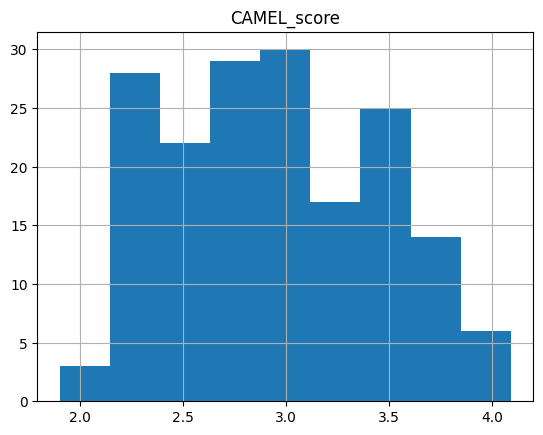

In [23]:
camel_pesos_sin_ponderar.hist(bins='sturges')

<Axes: >

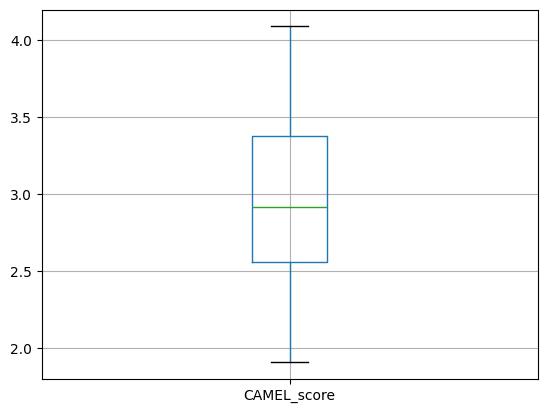

In [24]:
camel_pesos_sin_ponderar.boxplot()

array([[<Axes: title={'center': 'CAMEL_score'}>]], dtype=object)

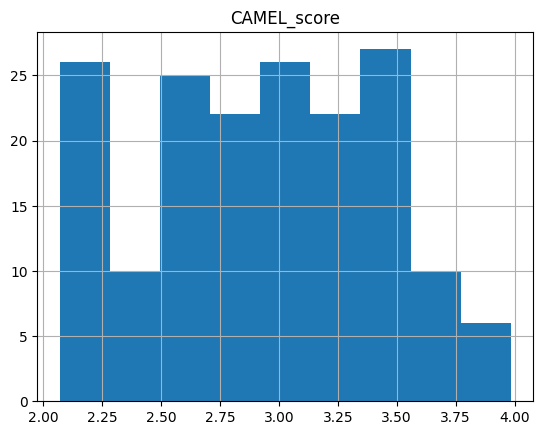

In [25]:
camel_pesos_ponderados.hist(bins='sturges')

<Axes: >

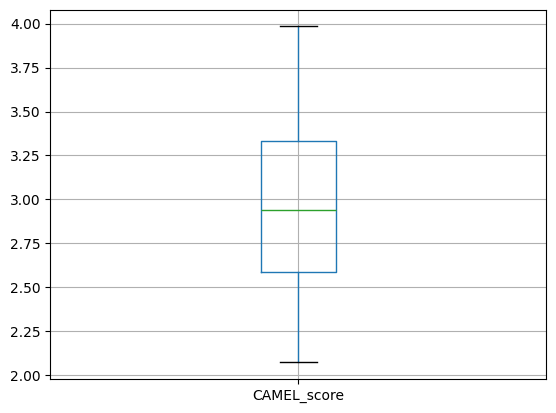

In [26]:
camel_pesos_ponderados.boxplot()

In [27]:
calificaciones_camel.to_csv(data_dir / "Calificaciones_CAMEL.csv", index=True)